# Grid Forecast Lab

A new implementation motivated by Zim Bela’s public fork of Rob Mulla’s hourly-demand tutorial. Predict each hour of the next day using only information available by 23:00. Compare against yesterday and last-week baselines.

This notebook executes the source-locked pipeline and renders its measured results. Author: Fatgezim “Zim” Bela. Original analysis/application code: MIT. Source data retain the license and credit recorded in `source-lock.json`.

In [1]:
from pathlib import Path
import json, numpy as np, pandas as pd
import matplotlib.pyplot as plt
import pipeline
from source import ROOT
plt.rcParams.update({'figure.figsize': (11,4), 'axes.spines.top':False, 'axes.spines.right':False, 'font.size':11})
print(json.dumps(json.loads((ROOT/'source-lock.json').read_text()), indent=2))

{
  "url": "https://www.kaggle.com/datasets/robikscube/hourly-energy-consumption",
  "download": "https://www.kaggle.com/api/v1/datasets/download/robikscube/hourly-energy-consumption?datasetVersionNumber=3",
  "version": 3,
  "sha256": "76636b1d976287a0fb1f0076a1be7767e053944c7080f3b8ad145d494c81bdea",
  "license": "CC0: Public Domain (Kaggle listing)",
  "classification": "Historical hourly demand observations",
  "credit": "PJM Interconnection; Kaggle distribution by Rob Mulla / robikscube."
}


## Execute the complete pipeline

The download is pinned by SHA-256. A mismatched archive stops the run. Model choices, seeds, parameters, preprocessing and artifact exports are implemented in `pipeline.py`.

In [2]:
report = pipeline.main()

{
  "quality": {
    "source_rows": 145366,
    "duplicate_timestamps": 4,
    "missing_hours": 30,
    "start": "2002-01-01 01:00:00",
    "end": "2018-08-03 00:00:00",
    "eligible_test_hours": 8732,
    "excluded_test_hours": 28,
    "train_hours": 121619,
    "calibration_hours": 8756
  },
  "winner": "Deeper boosting",
  "radius": 3891.9003368312915,
  "coverage": 0.8917773705909299,
  "metrics": [
    {
      "model": "Deeper boosting",
      "mae": 1853.843743157912,
      "rmse": 2471.8226003451737
    },
    {
      "model": "Yesterday",
      "mae": 2165.5852038479156,
      "rmse": 2969.8506265735678
    },
    {
      "model": "Last week",
      "mae": 3449.0079019697664,
      "rmse": 4705.922287225762
    }
  ],
  "mae_ci95": [
    1729.512742575059,
    1975.8714424089792
  ]
}


## Evaluation design

Train before 2014; evaluate candidate leaf counts on expanding 2014 and 2015 validation years. Select by hour-weighted validation MAE. Refit through 2015, calibrate the nominal 90% absolute-residual interval on 2016, and evaluate 2017 once. Replay uses observed lags from the prior day, while model weights stay fixed. The partial 2018 period is unused.

Source timestamps are naive. Average duplicate timestamps, insert a complete hourly index, preserve missing values, and exclude rows lacking a target or required feature. This clock convention is explicit; production timezone/DST correctness requires richer source metadata.

In [3]:
pd.DataFrame(report['candidates'])

,model,year,hours,mae,rmse
0,Compact boosting,2014,8732,1705.556085,2356.207705
1,Compact boosting,2015,8732,1692.451049,2288.273957
2,Deeper boosting,2014,8732,1679.086742,2333.545382
3,Deeper boosting,2015,8732,1697.829152,2307.073347


In [4]:
pd.DataFrame(report['metrics'])

,model,mae,rmse
0,Deeper boosting,1853.843743,2471.822600
1,Yesterday,2165.585204,2969.850627
2,Last week,3449.007902,4705.922287


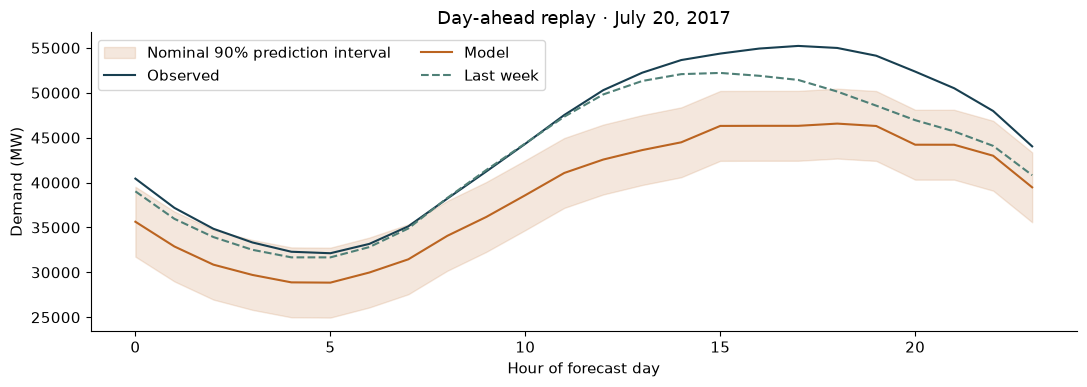

In [5]:
rows=pd.DataFrame(report['rows'])
day=rows[rows.date=='2017-07-20']
fig,ax=plt.subplots()
ax.fill_between(day.hour,day.lower,day.upper,color='#bb6420',alpha=.15,label='Nominal 90% prediction interval')
ax.plot(day.hour,day.actual,color='#183f50',label='Observed')
ax.plot(day.hour,day.forecast,color='#bb6420',label='Model')
ax.plot(day.hour,day.last_week,color='#4f8077',linestyle='--',label='Last week')
ax.set(xlabel='Hour of forecast day',ylabel='Demand (MW)',title='Day-ahead replay · July 20, 2017')
ax.legend(loc='upper left',ncol=2);plt.tight_layout();plt.show()

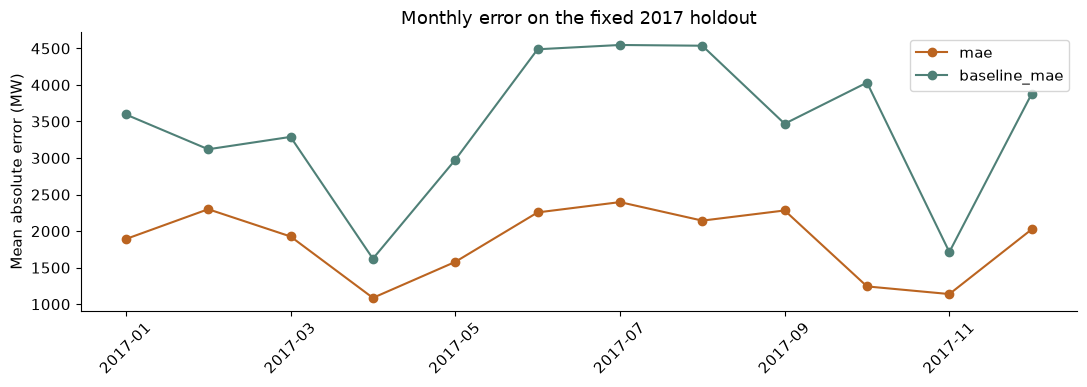

In [6]:
monthly=pd.DataFrame(report['monthly'])
ax=monthly.plot(x='month',y=['mae','baseline_mae'],marker='o',color=['#bb6420','#4f8077'])
ax.set(ylabel='Mean absolute error (MW)',xlabel='',title='Monthly error on the fixed 2017 holdout')
plt.xticks(rotation=45);plt.tight_layout();plt.show()

## What the result means

MAE measures the typical absolute hourly error; peak forecast error is a different decision. Compare the model with both baselines on identical eligible hours. The 95% MAE interval resamples whole days, retaining within-day correlation but not all seasonal dependence. Absolute-residual calibration assumes enough stability to transfer from 2016 to 2017; time dependence prevents an unconditional coverage guarantee. No forecast-weather inputs are used. A current utility system would require contemporary source data, validated time semantics and drift monitoring.

## Credit

[Owner notebook](https://www.kaggle.com/code/fatgezimbela/time-series-forecasting-with-machine-learning-yt) · [Rob Mulla tutorial](https://www.kaggle.com/code/robikscube/time-series-forecasting-with-machine-learning-yt) · [PJM data distribution](https://www.kaggle.com/datasets/robikscube/hourly-energy-consumption). The owner notebook is a credited tutorial fork; the benchmark here is a new implementation.

## Verify invariants

Tests check source/partition reconciliation and the properties that prevent misleading results.

In [7]:
import subprocess,sys
result=subprocess.run([sys.executable,'-m','pytest','tests','-q'],cwd=ROOT,capture_output=True,text=True)
print(result.stdout)
assert result.returncode==0, result.stderr

.....                                                                    [100%]
5 passed in 0.81s



## Reproduce and inspect

The README lists environment setup, app build and preview commands. `artifacts/test-predictions.csv` contains the held-out predictions; `artifacts/analysis.json` contains all application evidence. The app renders fixed, reproducible results and offers source inspection. Raw source archives and locally fitted models remain outside the public bundle; the locked downloader recreates them.